# 01 · EDA: Domain A (sách Tiki) vs Domain B (nhà hàng)

Theo kế hoạch đề tài: mục 6.2 (quy mô và sampling) và mục 7 (EDA, thực hiện riêng cho từng miền).

- Dữ liệu: `data/processed/` (tạo bằng `python -X utf8 -m src.build_dataset`), gộp train + val + test của từng miền.
- Đầu ra: biểu đồ trong `results/figures/eda_*.png`, bảng trong `results/metrics/eda_*.csv`.
- Màu cố định: **A = xanh**, **B = cam** (đã kiểm tra phân biệt được với người mù màu).

In [1]:
import json, os, re
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer

from src.config import LABEL_NAMES, PROCESSED, SEED
from src.dataset import load_split

FIG, MET = Path("results/figures"), Path("results/metrics")
FIG.mkdir(parents=True, exist_ok=True); MET.mkdir(parents=True, exist_ok=True)

COLOR = {"A": "#2a78d6", "B": "#eb6834"}
DOMAIN = {"A": "A · Sách (Tiki)", "B": "B · Nhà hàng"}
CLASSES = [LABEL_NAMES[k].capitalize() for k in (0, 1, 2)]
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.edgecolor": "#9a998f", "axes.labelcolor": "#3d3d3a", "xtick.color": "#5f5e57",
                     "ytick.color": "#5f5e57", "font.size": 10})
pd.set_option("display.max_colwidth", 80)

def save(fig, name):
    fig.savefig(FIG / f"eda_{name}.png", bbox_inches="tight", facecolor="white")

df = pd.concat([load_split(d, s) for d in "AB" for s in ("train", "val", "test")], ignore_index=True)
df["class"] = df["label"].map(lambda k: LABEL_NAMES[k].capitalize())
df["n_chars"] = df["text_clean"].str.len()
df.groupby(["domain", "split"]).size().unstack()

split,test,train,val
domain,,,
A,6393,51150,6393
B,6393,51150,6393


## 6.2 · Quy mô dữ liệu và phương pháp lấy mẫu

Từng bước của pipeline, đọc từ `data/processed/stats.json`.

In [2]:
stats = json.loads((PROCESSED / "stats.json").read_text(encoding="utf-8"))
STEP_NOTE = {
    "load": "Nguồn gốc: Tiki book CSV (A), res1 (B)",
    "relabel+row_filters": "Gán lại nhãn vùng xám theo nội dung + lọc review < 3 từ / rỗng",
    "dedup": "Bỏ trùng lặp trong từng miền",
    "cross_overlap": "Bỏ câu xuất hiện ở cả A và B",
    "extra_loaded": "Dữ liệu crawl: Tiki (chỉ 1–4★), Foody",
    "with_extra": "Gộp dữ liệu crawl (đã bỏ trùng với nguồn gốc)",
    "pool": "A bỏ bản crawl Tiki (lệch tỉ lệ); bỏ vùng xám chưa gán nhãn",
    "final": "Sau khi chia 80/10/10 theo sản phẩm/nhà hàng và lấy mẫu cho A = B",
}
rows = []
for s in stats["steps"]:
    for d in "AB":
        lab = {int(k): v for k, v in s[d]["labels"].items()}
        n = s[d]["n"]
        rows.append({"step": s["step"], "domain": d, "n": n,
                     **{f"{LABEL_NAMES[k]} %": round(100 * lab.get(k, 0) / n, 1) for k in (0, 1, 2)},
                     "ghi chú": STEP_NOTE.get(s["step"], "")})
pipeline = pd.DataFrame(rows)
pipeline.to_csv(MET / "eda_pipeline_steps.csv", index=False, encoding="utf-8-sig")
print("random seed:", stats["seed"])
pipeline

random seed: 42


,step,domain,n,negative %,neutral %,positive %,ghi chú
0,load,A,76536,6.6,5.1,88.3,"Nguồn gốc: Tiki book CSV (A), res1 (B)"
1,load,B,32713,19.0,20.4,60.6,"Nguồn gốc: Tiki book CSV (A), res1 (B)"
2,relabel+row_filters,A,70799,13.3,5.5,81.1,Gán lại nhãn vùng xám theo nội dung + lọc review < 3 từ / rỗng
3,relabel+row_filters,B,32508,20.9,8.6,70.4,Gán lại nhãn vùng xám theo nội dung + lọc review < 3 từ / rỗng
4,dedup,A,64750,14.1,5.8,80.1,Bỏ trùng lặp trong từng miền
5,dedup,B,31763,21.1,8.4,70.5,Bỏ trùng lặp trong từng miền
6,cross_overlap,A,64744,14.1,5.8,80.0,Bỏ câu xuất hiện ở cả A và B
7,cross_overlap,B,31757,21.1,8.4,70.5,Bỏ câu xuất hiện ở cả A và B
8,extra_loaded,A,41395,32.8,13.5,53.7,"Dữ liệu crawl: Tiki (chỉ 1–4★), Foody"
9,extra_loaded,B,56476,24.8,11.5,63.7,"Dữ liệu crawl: Tiki (chỉ 1–4★), Foody"


**Phương pháp lấy mẫu** (`src/split.py::full_split`): mỗi miền được chia thành 10 fold bằng `StratifiedGroupKFold`
(group = sản phẩm/nhà hàng, nên không có sản phẩm nào nằm ở hai split khác nhau). Một fold làm test, một fold làm val,
phần còn lại làm train. Sau đó **stratified sampling** theo tỉ lệ lớp gốc của từng miền, với cùng một tổng T cho
A và B. Miền lớn hơn (B) bị lấy mẫu bớt; tỉ lệ lớp của mỗi miền giữ nguyên như ở bước `pool`.

In [3]:
sizes = (df.groupby(["domain", "split"]).size().unstack()[["train", "val", "test"]]
         .assign(total=lambda t: t.sum(axis=1)))
pool = pipeline[pipeline.step == "pool"].set_index("domain")["n"]
sizes.insert(0, "pool (trước lấy mẫu)", pool)
sizes.to_csv(MET / "eda_dataset_sizes.csv", encoding="utf-8-sig")
sizes

split,pool (trước lấy mẫu),train,val,test,total
domain,,,,,
A,64744,51150,6393,6393,63936
B,81543,51150,6393,6393,63936


## 7.1 · Phân bố sentiment

In [4]:
dist = (df.groupby(["domain", "class"]).size().unstack()[CLASSES])
dist_pct = dist.div(dist.sum(axis=1), axis=0).mul(100).round(1)
by_split = (df.groupby(["domain", "split", "class"]).size().unstack()[CLASSES]
              .pipe(lambda t: t.div(t.sum(axis=1), axis=0).mul(100).round(1)))
table = pd.concat({"count": dist, "%": dist_pct}, axis=1)
table["imbalance (max/min)"] = (dist.max(axis=1) / dist.min(axis=1)).round(1)
table.to_csv(MET / "eda_label_distribution.csv", encoding="utf-8-sig")
by_split.to_csv(MET / "eda_label_distribution_by_split.csv", encoding="utf-8-sig")
display(table); by_split

count                         %                  imbalance (max/min)
class  Negative Neutral Positive Negative Neutral Positive                    
domain                                                                        
A          9025    3730    51181     14.1     5.8     80.1                13.7
B         16174    5242    42520     25.3     8.2     66.5                 8.1

class         Negative  Neutral  Positive
domain split                             
A      test       14.1      5.8      80.1
       train      14.1      5.8      80.0
       val        14.1      5.8      80.1
B      test       25.3      8.2      66.5
       train      25.3      8.2      66.5
       val        25.3      8.2      66.5

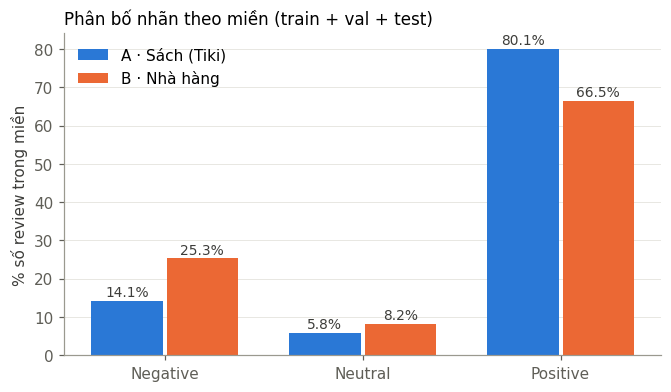

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.8))
x, w = np.arange(len(CLASSES)), 0.36
for i, d in enumerate("AB"):
    vals = dist_pct.loc[d, CLASSES].values
    bars = ax.bar(x + (i - 0.5) * (w + 0.02), vals, w, color=COLOR[d], label=DOMAIN[d])
    for b, v in zip(bars, vals):
        ax.annotate(f"{v:.1f}%", (b.get_x() + b.get_width() / 2, v), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=9, color="#3d3d3a")
ax.set_xticks(x, CLASSES); ax.set_ylabel("% số review trong miền"); ax.grid(axis="x", visible=False)
ax.set_title("Phân bố nhãn theo miền (train + val + test)", loc="left", fontsize=11)
ax.legend(frameon=False); save(fig, "label_distribution"); plt.show()

**Nhận xét:**
- Cả hai miền đều **mất cân bằng mạnh**: Positive chiếm đa số, còn Neutral là lớp hiếm nhất
  (5,8% ở A, 8,2% ở B). Tỉ lệ lớp lớn nhất / lớp nhỏ nhất là 13,7 ở A và 8,1 ở B.
- A lệch hơn B: Positive chiếm 80,1% ở A và 66,5% ở B; Negative ở B (25,3%) nhiều gần gấp đôi A (14,1%).
- Tỉ lệ lớp giống nhau ở train, val và test, nên việc chia tập đã giữ đúng phân bố.
- Hệ quả: dùng **Macro-F1** làm chỉ số chính, và có cơ sở để thử **Focal Loss** (mục 14).
  Tỉ lệ lớp khác nhau giữa A và B (label shift) cũng là một phần của domain shift khi chạy A→B và B→A.

## 7.2 · Độ dài văn bản

In [6]:
length = (df.groupby("domain")[["n_chars", "n_words"]]
            .describe(percentiles=[.25, .5, .75, .95]).round(1))
length_by_class = df.groupby(["domain", "class"])["n_words"].agg(["mean", "median", "min", "max"]).round(1)
length.to_csv(MET / "eda_length_stats.csv", encoding="utf-8-sig")
length_by_class.to_csv(MET / "eda_length_by_class.csv", encoding="utf-8-sig")
display(length.T); length_by_class.unstack(0)

domain               A        B
n_chars count  63936.0  63936.0
        mean     160.5    283.0
        std      212.8    267.0
        min        7.0      8.0
        25%       55.0    107.0
        50%      102.0    200.0
        75%      189.0    387.0
        95%      472.0    786.0
        max     5443.0   4978.0
n_words count  63936.0  63936.0
        mean      36.1     65.0
        std       47.8     61.4
        min        3.0      3.0
        25%       12.0     24.0
        50%       23.0     46.0
        75%       43.0     89.0
        95%      106.0    181.0
        max     1220.0   1159.0

mean       median       min      max      
domain       A     B      A     B   A  B     A     B
class                                               
Negative  38.9  87.8   28.0  65.0   3  3   776  1159
Neutral   39.1  73.3   28.0  59.0   3  3   693   735
Positive  35.4  55.3   22.0  38.0   3  3  1220   769

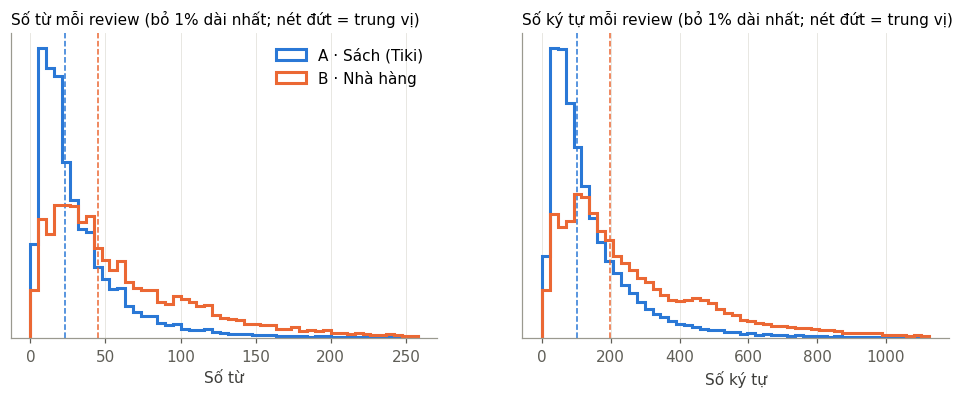

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, title in ((axes[0], "n_words", "Số từ"), (axes[1], "n_chars", "Số ký tự")):
    cap = df[col].quantile(0.99)
    bins = np.linspace(0, cap, 50)
    for d in "AB":
        v = df.loc[df.domain == d, col]
        v = v[v <= cap]
        ax.hist(v, bins=bins, histtype="step", linewidth=2, color=COLOR[d], density=True, label=DOMAIN[d])
        ax.axvline(v.median(), color=COLOR[d], linewidth=1, linestyle="--")
    ax.set_title(f"{title} mỗi review (bỏ 1% dài nhất; nét đứt = trung vị)", loc="left", fontsize=10)
    ax.set_xlabel(title); ax.set_yticks([]); ax.grid(axis="y", visible=False)
axes[0].legend(frameon=False)
save(fig, "length_hist"); plt.show()

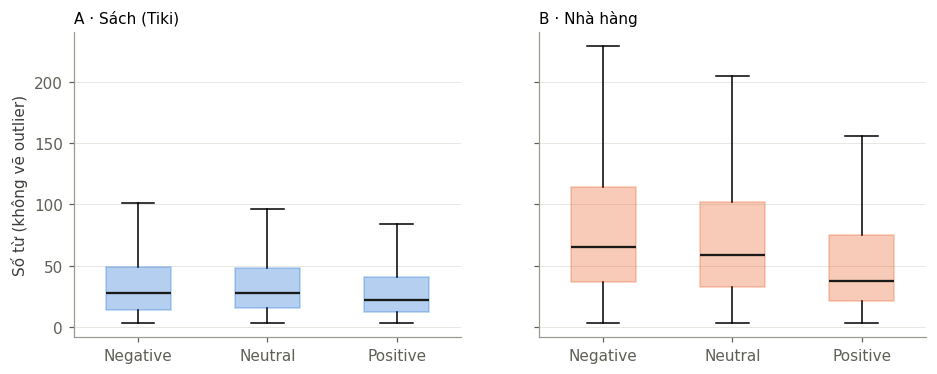

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, d in zip(axes, "AB"):
    data = [df.loc[(df.domain == d) & (df["class"] == c), "n_words"] for c in CLASSES]
    bp = ax.boxplot(data, showfliers=False, widths=0.5, patch_artist=True,
                    medianprops={"color": "#1a1a19", "linewidth": 1.5})
    for p in bp["boxes"]:
        p.set(facecolor=COLOR[d], alpha=0.35, edgecolor=COLOR[d])
    ax.set_xticks([1, 2, 3], CLASSES); ax.set_title(DOMAIN[d], loc="left", fontsize=10)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Số từ (không vẽ outlier)")
save(fig, "length_by_class"); plt.show()

**Nhận xét:**
- Review nhà hàng (B) **dài gấp đôi** review sách (A): trung vị 46 từ so với 23 từ (200 ký tự so với 102 ký tự).
  Cả hai phân bố đều lệch phải; review dài nhất lên tới khoảng 1.200 từ.
- Trong từng miền, review Negative và Neutral dài hơn Positive. Trung vị ở A là 28 / 28 / 22 từ,
  ở B là 65 / 59 / 38 từ: người dùng hay giải thích khi chê, còn khen thì thường ngắn gọn.
- Hệ quả khi chạy cross-domain: mô hình train trên A chủ yếu gặp câu ngắn; khi chuyển sang B sẽ gặp câu dài, nhiều ý.
  Với PhoBERT cần chọn `max_length` dựa trên phân vị 95 của miền dài hơn (B: 181 từ).

## 7.3 · Phân tích từ vựng

Dùng cột `text_ml` (đã tách từ bằng VnCoreNLP, ví dụ `nhân_viên`, không có dấu câu). Bảng tần suất bỏ một danh sách
stopword ngắn (hư từ, đại từ); danh sách này chỉ dùng cho EDA, mô hình vẫn học trên toàn bộ văn bản.

In [9]:
STOP = set('''và là của có cho thì mà với cũng được này đó nên khi đã rồi nhưng như lại ra vào trong
mình tôi bạn em anh chị mọi_người nó họ ai các những một cái con ở để đến từ về theo nếu vì do bị
thì_là nhé nha ạ ơi à ừ luôn vẫn còn đang sẽ hơi rất quá lắm nhiều ít hơn nhất thấy đi làm
'''.split())
tok = lambda s: [w for w in s.split() if w not in STOP and not w.isdigit()]

def top_ngrams(texts, n, k=20):
    cv = CountVectorizer(analyzer=lambda s: (lambda t: [" ".join(t[i:i + n]) for i in range(len(t) - n + 1)])(tok(s)),
                         min_df=5)
    counts = np.asarray(cv.fit_transform(texts).sum(axis=0)).ravel()
    return pd.Series(counts, index=cv.get_feature_names_out()).nlargest(k)

tops = {(d, n): top_ngrams(df.loc[df.domain == d, "text_ml"], n) for d in "AB" for n in (1, 2)}
out = pd.concat({f"{d}_{'uni' if n == 1 else 'bi'}gram": s.reset_index().set_axis(["term", "count"], axis=1)
                 for (d, n), s in tops.items()}, axis=1)
out.to_csv(MET / "eda_top_ngrams.csv", index=False, encoding="utf-8-sig")
out

A_unigram                  A_bigram         B_unigram         \
        term  count               term  count       term  count   
0       sách  73991          giao hàng  14361         ăn  76520   
1      không  32794          cuốn sách   9760      không  75266   
2        đọc  26910         hàng nhanh   8796       quán  53529   
3       giao  22844           sách đẹp   6514       ngon  51850   
4       hàng  22115           sách hay   5805        món  27868   
5        hay  17603         quyển sách   4020        đây  27116   
6       cuốn  17377          tiki giao   3819  nhân_viên  22407   
7      nhanh  16069          mọi người   3422        lần  19959   
8        đẹp  15908         sách không   3247        khá  19292   
9       tiki  14890         giao nhanh   3221      người  16852   
10       mua  14311           chưa đọc   2927      đồ_ăn  16373   
11  nội_dung  13983  đóng_gói cẩn_thận   2867    phục_vụ  15643   
12     người  12999           sách mới   2821        gọi  15171   
13       mới   9930      nội_dung sách   2259        giá  13706   
14  đóng_gói   8895            dễ hiểu   2183       thịt  13565   
15     quyển   8115         nhanh sách   2147       phải  13428   
16      chưa   7829           mua sách   2054         vị  13122   
17       bìa   7797          người đọc   1803       nước  13061   
18       tốt   7597           bìa sách   1711      khách  12273   
19       khá   7272     nhanh đóng_gói   1646        nữa  12097   

             B_bigram        
                 term count  
0              món ăn  6033  
1             ăn ngon  4781  
2           mọi người  4007  
3          đồ_ăn ngon  3935  
4          không ngon  3265  
5            ăn không  3023  
6          không phải  2981  
7   nhân_viên phục_vụ  2976  
8          không biết  2933  
9             đồ uống  2923  
10            trà sữa  2895  
11           ăn_ở đây  2740  
12             ăn thử  2725  
13           khá ngon  2545  
14             đây ăn  2508  
15          chứ không  2356  
16            lần đầu  2171  
17            quán ăn  2150  
18           không gì  2108  
19           chủ quán  2076

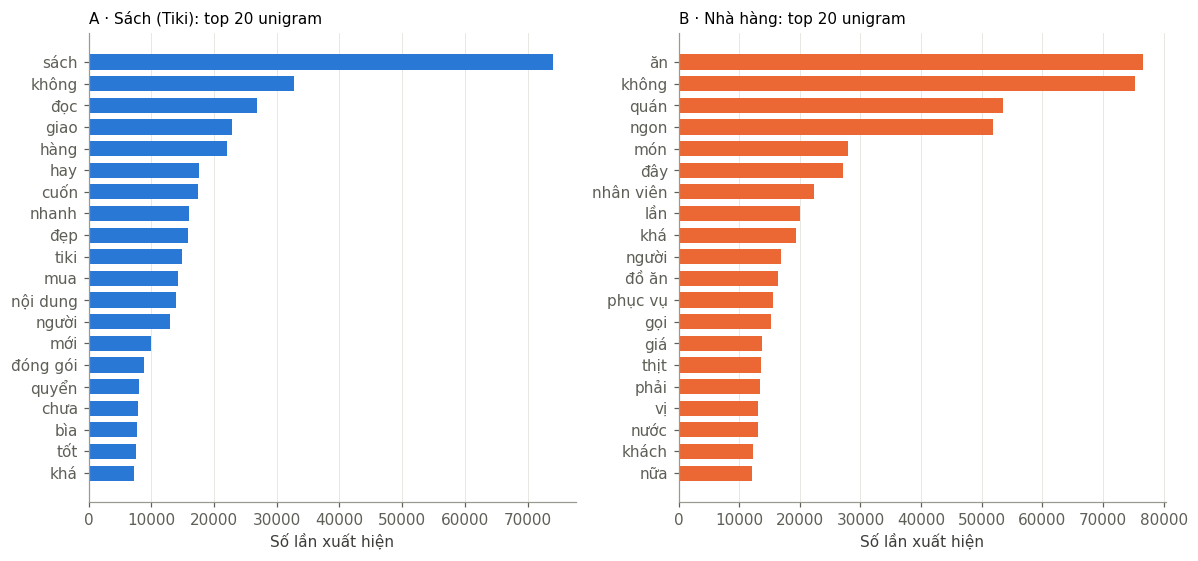

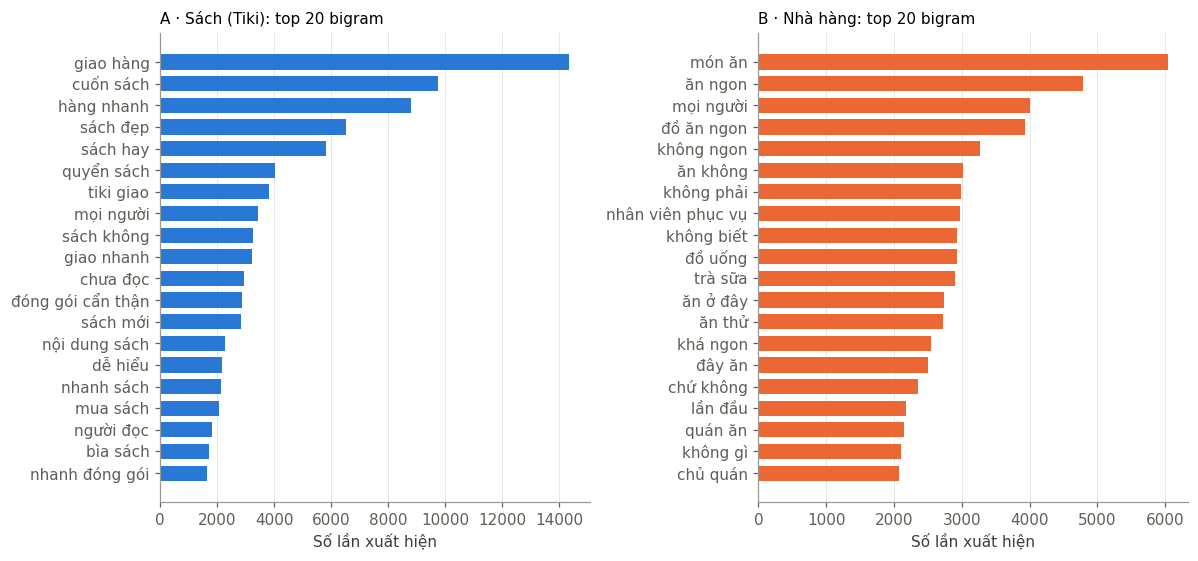

In [10]:
for n, name in ((1, "unigrams"), (2, "bigrams")):
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
    for ax, d in zip(axes, "AB"):
        s = tops[(d, n)].iloc[::-1]
        ax.barh(s.index.str.replace("_", " "), s.values, color=COLOR[d], height=0.7)
        ax.set_title(f"{DOMAIN[d]}: top 20 {'unigram' if n == 1 else 'bigram'}", loc="left", fontsize=10)
        ax.grid(axis="y", visible=False); ax.set_xlabel("Số lần xuất hiện")
    fig.tight_layout(); save(fig, f"top_{name}"); plt.show()

### Từ khoá đặc trưng của từng miền

Dùng **log-odds ratio với informative Dirichlet prior** (Monroe và cộng sự, 2008): z-score dương nghĩa là từ đó
đặc trưng cho A, âm nghĩa là đặc trưng cho B. Cách này ổn định hơn so sánh tần suất thô, vì không bị các từ hiếm chi phối.

In [11]:
cv = CountVectorizer(analyzer=tok, min_df=10)
X = cv.fit_transform(df["text_ml"])
vocab = cv.get_feature_names_out()
yA = np.asarray(X[(df.domain == "A").values].sum(axis=0)).ravel()
yB = np.asarray(X[(df.domain == "B").values].sum(axis=0)).ravel()
alpha = (yA + yB) * 0.01 + 0.01  # prior proportional to the pooled frequency
a0, nA, nB = alpha.sum(), yA.sum(), yB.sum()
delta = (np.log((yA + alpha) / (nA + a0 - yA - alpha)) - np.log((yB + alpha) / (nB + a0 - yB - alpha)))
z = delta / np.sqrt(1 / (yA + alpha) + 1 / (yB + alpha))
kw = pd.DataFrame({"term": vocab, "z": z, "count_A": yA, "count_B": yB}).sort_values("z")
keywords = pd.concat([kw.tail(20).iloc[::-1].assign(domain="A"), kw.head(20).assign(domain="B")])
keywords.round(2).to_csv(MET / "eda_domain_keywords.csv", index=False, encoding="utf-8-sig")
keywords.round(1)

,term,z,count_A,count_B,domain
6840,sách,154.0,73991,185,A
2495,giao,139.6,22844,2865,A
3062,hàng,138.6,22115,4193,A
9864,đọc,125.3,26910,802,A
1626,cuốn,118.1,17377,1552,A
9801,đẹp,113.1,15908,4680,A
5318,nhanh,111.9,16069,5206,A
2830,hay,103.7,17603,8715,A
4575,mua,96.0,14311,6594,A
9631,đóng_gói,82.5,8895,655,A


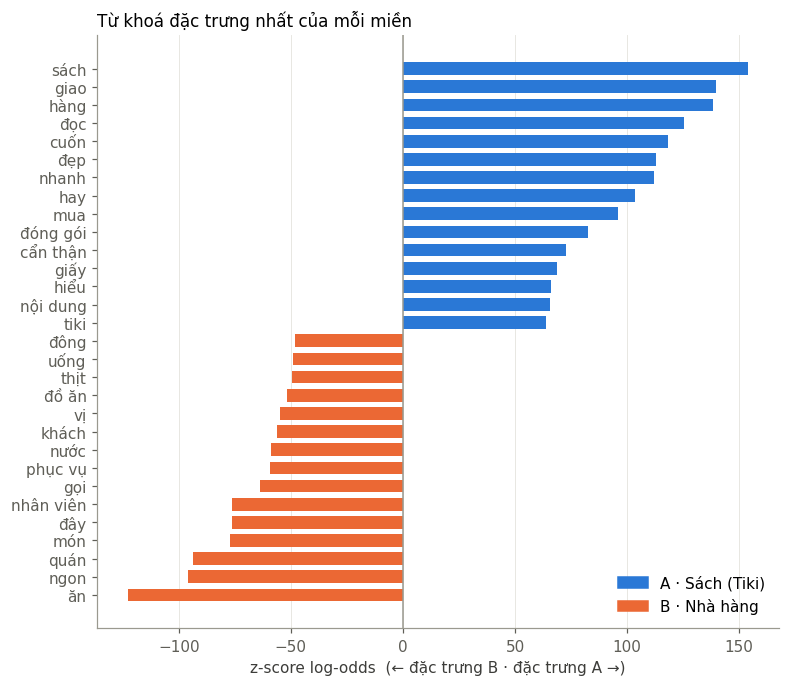

In [12]:
k = pd.concat([kw.head(15), kw.tail(15)])
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(k["term"].str.replace("_", " "), k["z"], color=[COLOR["A"] if v > 0 else COLOR["B"] for v in k["z"]],
        height=0.7)
ax.axvline(0, color="#9a998f", linewidth=1); ax.grid(axis="y", visible=False)
ax.set_xlabel("z-score log-odds  (← đặc trưng B · đặc trưng A →)")
ax.set_title("Từ khoá đặc trưng nhất của mỗi miền", loc="left", fontsize=11)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COLOR[d], label=DOMAIN[d]) for d in "AB"], frameon=False, loc="lower right")
save(fig, "domain_keywords"); plt.show()

## 7.4 · So sánh từ vựng giữa hai miền

Các chỉ số ở đây giúp giải thích domain shift. Đáng chú ý nhất là **OOV**: tỉ lệ token ở miền đích (test) không có
trong từ vựng của train miền nguồn. Đây chính là phần mà TF-IDF train trên miền nguồn không thể nhìn thấy.

In [13]:
def vocab_of(mask, min_df=1):
    c = CountVectorizer(analyzer=str.split, min_df=min_df).fit(df.loc[mask, "text_ml"])
    return set(c.vocabulary_)

def oov_rate(src_vocab, texts):
    toks = [w for s in texts for w in s.split()]
    return 100 * sum(w not in src_vocab for w in toks) / len(toks)

train = {d: (df.domain == d) & (df.split == "train") for d in "AB"}
test = {d: df.loc[(df.domain == d) & (df.split == "test"), "text_ml"] for d in "AB"}
V = {d: vocab_of(train[d]) for d in "AB"}
V5 = {d: vocab_of(train[d], min_df=5) for d in "AB"}
rows = [{"chỉ số": "Vocab train (min_df=1)", "A": len(V["A"]), "B": len(V["B"])},
        {"chỉ số": "Vocab train (min_df=5)", "A": len(V5["A"]), "B": len(V5["B"])},
        {"chỉ số": "Jaccard vocab A∩B / A∪B (min_df=5) %", "A": round(100 * len(V5["A"] & V5["B"]) / len(V5["A"] | V5["B"]), 1), "B": None},
        {"chỉ số": "OOV % token test, in-domain (X→X)", "A": round(oov_rate(V["A"], test["A"]), 2), "B": round(oov_rate(V["B"], test["B"]), 2)},
        {"chỉ số": "OOV % token test, cross-domain (nguồn khác → X)", "A": round(oov_rate(V["B"], test["A"]), 2), "B": round(oov_rate(V["A"], test["B"]), 2)}]
vocab_cmp = pd.DataFrame(rows).set_index("chỉ số")
vocab_cmp.to_csv(MET / "eda_vocab_comparison.csv", encoding="utf-8-sig")
vocab_cmp

,A,B
chỉ số,,
Vocab train (min_df=1),22595.00,28239.00
Vocab train (min_df=5),7492.00,9595.00
Jaccard vocab A∩B / A∪B (min_df=5) %,38.80,NaN
"OOV % token test, in-domain (X→X)",0.71,0.44
"OOV % token test, cross-domain (nguồn khác → X)",3.50,3.59


In [14]:
# Từ cảm xúc chung: tỉ lệ Positive trong số review chứa từ đó, so giữa hai miền
probe = ["hài_lòng", "ngon", "tốt", "đẹp", "nhanh", "ổn", "bình_thường", "tạm", "thất_vọng", "tệ", "đắt", "rẻ", "chậm", "lâu"]
r = []
for w in probe:
    for d in "AB":
        m = (df.domain == d) & df["text_ml"].str.contains(rf"(?:^| ){w}(?: |$)")
        if m.sum():
            r.append({"term": w, "domain": d, "n_reviews": int(m.sum()),
                      **{f"% {c}": round(100 * (df.loc[m, 'class'] == c).mean(), 1) for c in CLASSES}})
polarity = pd.DataFrame(r).set_index(["term", "domain"])
polarity.to_csv(MET / "eda_term_polarity.csv", encoding="utf-8-sig")
polarity.unstack("domain")

n_reviews        % Negative       % Neutral       % Positive      
domain              A      B          A     B         A     B          A     B
term                                                                          
bình_thường       483   3348       24.4  45.5      21.9  21.8       53.6  32.7
chậm              576   1202       24.5  46.8      10.6  15.6       64.9  37.7
hài_lòng         2970   1827       14.9  20.9       3.1   4.6       81.9  74.5
lâu              1781   4800       17.8  36.6       7.3  11.8       74.9  51.5
ngon              134  37001        1.5  12.2       3.0   7.1       95.5  80.6
nhanh           15772   4879        4.5  12.2       4.6   9.7       90.9  78.2
rẻ               1225   4705        6.2  16.9       2.9  10.6       90.9  72.5
thất_vọng        1907   2283       63.7  81.1       5.1   3.9       31.3  15.0
tạm               475   2087       16.2  39.9      40.4  30.9       43.4  29.2
tệ                821   2869       79.4  90.3       7.2   4.4       13.4   5.3
tốt              6952   4215        7.9  21.4       5.8   8.6       86.3  70.0
đắt               154   2112       42.9  39.9       4.5  16.2       52.6  43.9
đẹp             14791   4147        3.1  11.0       4.4  10.0       92.5  79.0
ổn               2401   4937        9.6  17.4      18.6  19.8       71.8  62.7

**Nhận xét** (đọc cùng các bảng và biểu đồ ở trên):
- **Hai miền có hai bộ từ khoá tách biệt.** A xoay quanh sách và trải nghiệm mua hàng (sách, đọc, cuốn, giấy,
  nội dung, giao hàng, đóng gói, tiki), còn B xoay quanh món ăn và dịch vụ (ăn, ngon, quán, món, nhân viên,
  phục vụ, gọi, thịt). Điều này khớp với giả thuyết ở mục 7.4 của kế hoạch.
- **Từ vựng giao nhau ít**: chỉ 38,8% từ vựng (các từ xuất hiện ít nhất 5 lần) là chung giữa hai miền.
  Tỉ lệ token OOV khi chạy cross-domain là khoảng 3,5%, gấp 5–8 lần so với in-domain (0,4–0,7%).
  Con số này không lớn về tổng thể, nhưng các token OOV lại thường là từ đặc trưng của miền, mà TF-IDF train trên
  miền nguồn thì không có trọng số cho chúng.
- **Cùng một từ có thể mang sắc thái khác nhau theo miền** (bảng polarity):
  - "chậm": ở A có 65% review là Positive (thường là "giao chậm nhưng sách hay"), ở B có 47% là Negative.
  - "lâu": Negative 18% ở A so với 37% ở B.
  - "bình thường": Negative 24% ở A so với 46% ở B.
  - "ngon" xuất hiện 37.001 lần ở B nhưng chỉ 134 lần ở A.

  Đây là nguồn lỗi kiểu 16.8 trong Error Analysis.
- Ba yếu tố cùng tạo nên domain shift: **khác từ vựng**, **khác độ dài** (B dài gần gấp đôi) và **khác tỉ lệ lớp**
  (A lệch Positive hơn). Các bảng này được dùng lại khi giải thích Performance Drop ở mục 12.